# ENZERA - 01 Exploratory data analysis (SGCC)

All analysis is on the **train split only** (70% of customers), created with exactly the same
`train_test_split` calls and seed (42) as `ml/train.py`. The test and demo customers are never looked at here,
so nothing we learn from EDA leaks into evaluation.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from ml.features import FEATURE_INFO, FEATURE_NAMES, clean, compute_features, monthly_means, split_wide

SEED = 42
plt.rcParams["figure.dpi"] = 100
BLUE, RED = "#4C78A8", "#E45756"
ids, labels, dates, values = split_wide(pd.read_csv(ROOT / "data/raw/data.csv"))
print(f"{len(ids):,} customers x {len(dates):,} days, {dates.min().date()} to {dates.max().date()}")

42,372 customers x 1,034 days, 2014-01-01 to 2016-10-31


## Same split as `ml/train.py`

In [2]:
idx = np.arange(len(ids))
tr, rest = train_test_split(idx, test_size=0.30, stratify=labels, random_state=SEED)
te, demo = train_test_split(rest, test_size=0.50, stratify=labels[rest], random_state=SEED)

split = json.loads((ROOT / "reports/metrics.json").read_text())["dataset"]["split"]
assert (len(tr), len(te), len(demo)) == (split["train"], split["test"], split["demo"])
print("train / test / demo =", len(tr), len(te), len(demo), "(matches reports/metrics.json)")

V, y = values[tr], labels[tr]   # everything below uses the train split only
X = clean(V)
M = monthly_means(X, dates)
months = dates.to_period("M").unique().to_timestamp()

train / test / demo = 29660 6356 6356 (matches reports/metrics.json)


## 1. Class imbalance

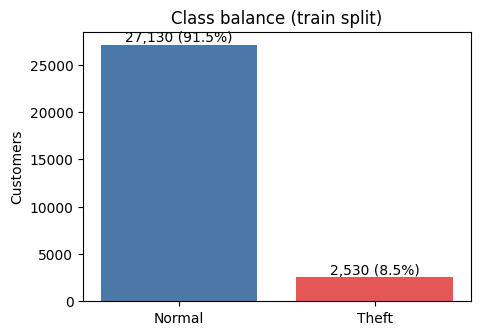

Normal 27,130, theft 2,530, ratio 1 : 10.7


In [3]:
counts = np.bincount(y)
fig, ax = plt.subplots(figsize=(5, 3.5))
ax.bar(["Normal", "Theft"], counts, color=[BLUE, RED])
for i, c in enumerate(counts):
    ax.text(i, c, f"{c:,} ({c / counts.sum():.1%})", ha="center", va="bottom")
ax.set_ylabel("Customers"); ax.set_title("Class balance (train split)")
plt.show()
print(f"Normal {counts[0]:,}, theft {counts[1]:,}, ratio 1 : {counts[0] / counts[1]:.1f}")

**Observation.** The train split has 27,130 normal and 2,530 theft customers (8.5% theft, about 1 thief per 10.7 normal customers). A model that always says "normal" would be 91.5% accurate and catch zero thieves, so accuracy is useless here. We use precision, recall, F1, PR-AUC and "theft caught in the top 10%", and handle the imbalance with class weights (`scale_pos_weight`) in XGBoost.

## 2. Missing data

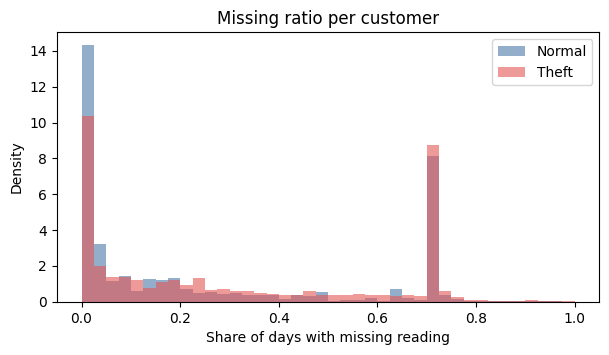

Overall share of missing cells: 25.7%


,median missing ratio,mean missing ratio,customers with no missing day,customers with >50% missing,no reading at all before 2016
Normal,0.097,0.252,0.0,0.258,0.220
Theft,0.214,0.313,0.0,0.327,0.246


In [4]:
miss = np.isnan(V).mean(axis=1)
fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(0, 1, 41)
ax.hist(miss[y == 0], bins=bins, color=BLUE, alpha=0.6, density=True, label="Normal")
ax.hist(miss[y == 1], bins=bins, color=RED, alpha=0.6, density=True, label="Theft")
ax.set_xlabel("Share of days with missing reading"); ax.set_ylabel("Density"); ax.legend()
ax.set_title("Missing ratio per customer")
plt.show()

print(f"Overall share of missing cells: {np.isnan(V).mean():.1%}")
tbl = pd.DataFrame({
    "median missing ratio": [np.median(miss[y == k]) for k in (0, 1)],
    "mean missing ratio": [miss[y == k].mean() for k in (0, 1)],
    "customers with no missing day": [(miss[y == k] == 0).mean() for k in (0, 1)],
    "customers with >50% missing": [(miss[y == k] > 0.5).mean() for k in (0, 1)],
    "no reading at all before 2016": [np.isnan(V[y == k][:, dates.year < 2016]).all(axis=1).mean() for k in (0, 1)],
}, index=["Normal", "Theft"])
tbl.round(3)

**Observation.** Missing data is heavy: 25.7% of all readings are missing. The histogram has two peaks: most customers miss under 10% of days, but a second large group misses about 71% of days. Thieves miss more on average (median 9.7% for normal vs 21.4% for theft), so `missing_ratio` is kept as a feature. Every customer has at least one missing day, so imputation is unavoidable.

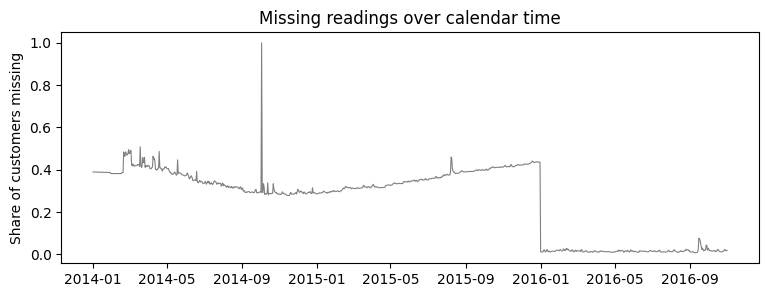

Share of customers missing, by year:
2014    0.353
2015    0.361
2016    0.016


In [5]:
per_day = pd.Series(np.isnan(V).mean(axis=0), index=dates)
fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(per_day.index, per_day.values, color="grey", lw=0.8)
ax.set_ylabel("Share of customers missing"); ax.set_title("Missing readings over calendar time")
plt.show()
print("Share of customers missing, by year:")
print(per_day.groupby(per_day.index.year).mean().round(3).to_string())

**Observation.** Missing readings are not random in time: around 35% of customers are missing on a typical day in 2014 and 2015, then it drops to 1.6% in 2016. The 71% peak above is the same effect. 22.3% of train customers (22.0% normal, 24.6% theft) have **no reading at all before 2016**, i.e. 730 of the 1,034 days. `ml/features.clean()` interpolates with `limit_direction="both"`, so for these customers the whole 2014-2015 gap is filled with a flat copy of their first 2016 value. This is a known limitation of our preprocessing (it can bias trend and variability features) and is listed in the report.

## 3. Zero-consumption days

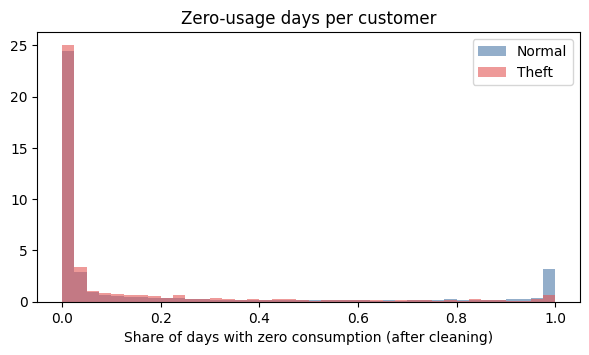

Median zero ratio - normal 0.007, theft 0.003


In [6]:
zero = (X <= 1e-6).mean(axis=1)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(zero[y == 0], bins=bins, color=BLUE, alpha=0.6, density=True, label="Normal")
ax.hist(zero[y == 1], bins=bins, color=RED, alpha=0.6, density=True, label="Theft")
ax.set_xlabel("Share of days with zero consumption (after cleaning)"); ax.legend()
ax.set_title("Zero-usage days per customer")
plt.show()
print(f"Median zero ratio - normal {np.median(zero[y == 0]):.3f}, theft {np.median(zero[y == 1]):.3f}")

**Observation.** Zero-consumption days are rare for both classes (median 0.7% for normal, 0.3% for theft). So in SGCC, theft is **not** mainly visible as long runs of zero usage. Thieves actually have slightly fewer zero days, which matches the single-feature AUCs below 0.5 for `zero_ratio` and `longest_zero_run`.

## 4. Thieves vs normal customers

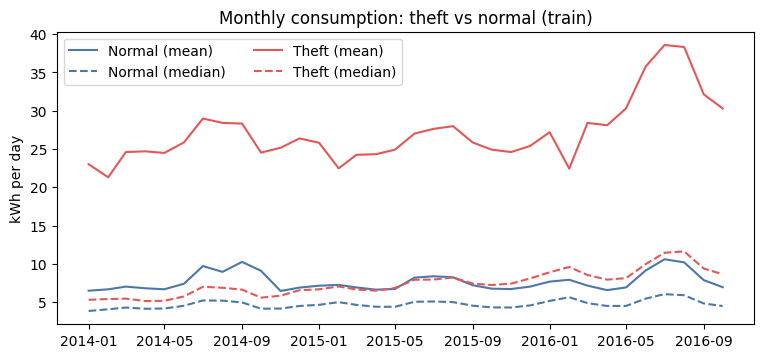

Normal: mean daily kWh 7.69, median of customer means 5.19
Theft: mean daily kWh 27.16, median of customer means 8.32


In [7]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for k, name, col in [(0, "Normal", BLUE), (1, "Theft", RED)]:
    ax.plot(months, M[y == k].mean(axis=0), color=col, label=f"{name} (mean)")
    ax.plot(months, np.median(M[y == k], axis=0), color=col, ls="--", label=f"{name} (median)")
ax.set_ylabel("kWh per day"); ax.legend(ncol=2); ax.set_title("Monthly consumption: theft vs normal (train)")
plt.show()
for k, name in [(0, "Normal"), (1, "Theft")]:
    print(f"{name}: mean daily kWh {X[y == k].mean():.2f}, median of customer means {np.median(X[y == k].mean(axis=1)):.2f}")

**Observation.** Counter-intuitively, customers labelled as theft consume **more** on average than normal customers: mean daily usage 27.16 kWh vs 7.69 kWh (median of customer means 8.32 vs 5.19). The mean curve for theft is pulled up by a few very large consumers, but the median curve is higher too. Both classes have the same seasonal shape, with summer peaks in 2014 and 2016. Theft customers rise more strongly in 2016, which shows up later as a higher `recent_vs_past` and `trend_slope`. Likely explanation: SGCC labels come from inspections, and utilities tend to inspect larger, more irregular consumers (an assumption we cannot verify from the data).

In [8]:
F = compute_features(V, dates)
rows = []
for f in FEATURE_NAMES:
    a, b = F.loc[y == 0, f], F.loc[y == 1, f]
    rows.append({"feature": f, "meaning": FEATURE_INFO[f],
                 "median normal": a.median(), "median theft": b.median(),
                 "single-feature ROC-AUC": roc_auc_score(y, F[f])})
feat_tbl = pd.DataFrame(rows).set_index("feature")
feat_tbl["separation |AUC-0.5|"] = (feat_tbl["single-feature ROC-AUC"] - 0.5).abs()
feat_tbl.sort_values("separation |AUC-0.5|", ascending=False).round(3)

,meaning,median normal,median theft,single-feature ROC-AUC,separation |AUC-0.5|
feature,,,,,
std_daily,Day-to-day variation (kWh),2.530,5.174,0.705,0.205
max_daily,Highest daily consumption (kWh),14.235,25.253,0.693,0.193
mean_daily,Average daily consumption (kWh),5.187,8.320,0.654,0.154
recent_vs_past,Recent usage compared with earlier usage,1.006,1.243,0.613,0.113
trend_slope,Long-term trend of monthly usage,0.003,0.016,0.612,0.112
monthly_cv,Variability between months,0.379,0.517,0.593,0.093
cv_daily,Relative variability of consumption,0.493,0.634,0.575,0.075
missing_ratio,Share of days with missing readings,0.097,0.214,0.568,0.068
spike_ratio,Share of days with unusual spikes,0.045,0.048,0.547,0.047


*Single-feature ROC-AUC* = how well one feature alone ranks thieves above normal customers
(0.5 = useless, >0.5 = higher values mean more theft, <0.5 = lower values mean more theft).

**Observation.** No single feature separates the classes well: the best, `std_daily`, reaches only ROC-AUC 0.705 on its own. Magnitude and variability features (`std_daily` 0.705, `max_daily` 0.693, `mean_daily` 0.654) separate best, followed by change-over-time features (`recent_vs_past` 0.613, `trend_slope` 0.612). Zero-usage features and `weekend_ratio` are almost uninformative alone (0.46-0.53). Because each feature is weak alone, a model that combines them (XGBoost, which also learns interactions) is needed.

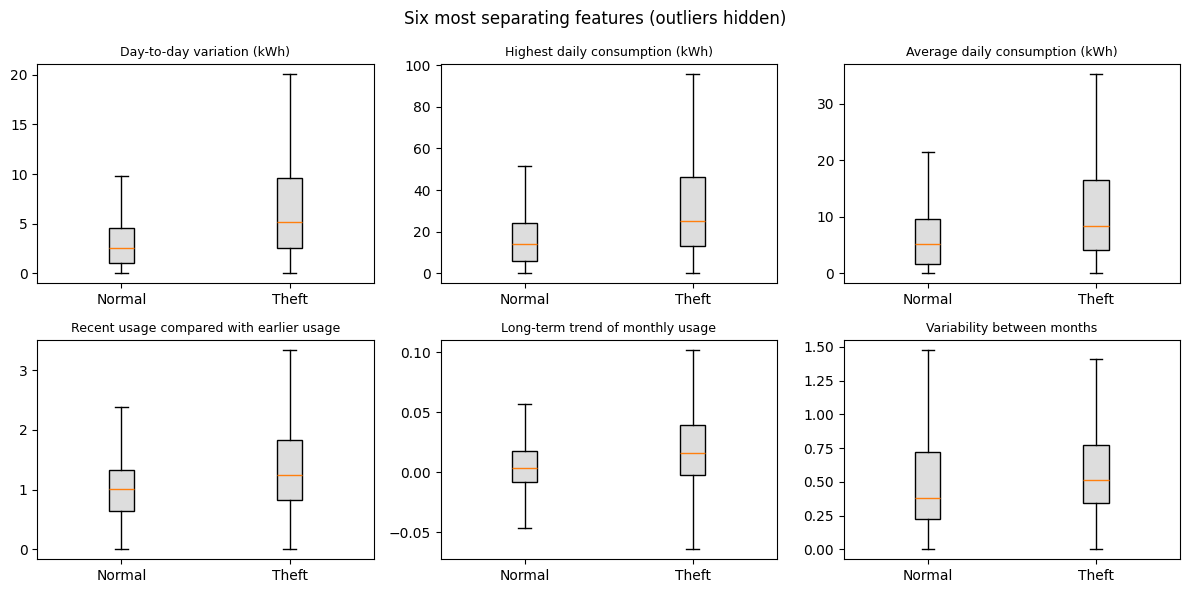

In [9]:
top6 = feat_tbl.sort_values("separation |AUC-0.5|", ascending=False).index[:6]
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, f in zip(axes.ravel(), top6):
    data = [F.loc[y == 0, f], F.loc[y == 1, f]]
    ax.boxplot(data, tick_labels=["Normal", "Theft"], showfliers=False, patch_artist=True,
               boxprops=dict(facecolor="#ddd"))
    ax.set_title(FEATURE_INFO[f], fontsize=9)
fig.suptitle("Six most separating features (outliers hidden)")
fig.tight_layout(); plt.show()

**Observation.** The boxes overlap a lot for all six features, which explains why precision and recall stay moderate (about 0.36 for XGBoost). Theft customers have higher and more spread-out values for day-to-day variation, peak usage and average usage, and their recent-vs-past ratio and trend are shifted upwards (median 1.24 vs 1.01, and 0.016 vs 0.003).

## 5. Sample consumption curves

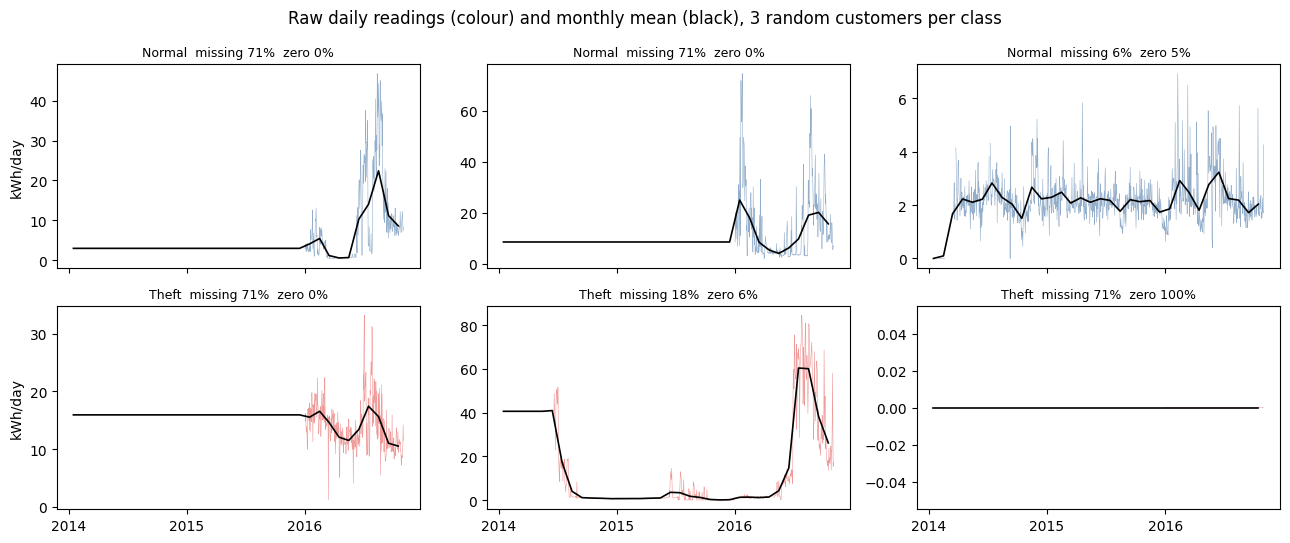

In [10]:
rng = np.random.default_rng(SEED)
fig, axes = plt.subplots(2, 3, figsize=(13, 5.5), sharex=True)
for row, (k, name, col) in enumerate([(0, "Normal", BLUE), (1, "Theft", RED)]):
    pick = rng.choice(np.flatnonzero(y == k), 3, replace=False)
    for ax, i in zip(axes[row], pick):
        ax.plot(dates, V[i], color=col, lw=0.4, alpha=0.6)
        ax.plot(months + pd.Timedelta(days=14), M[i], color="black", lw=1.2)
        ax.set_title(f"{name}  missing {np.isnan(V[i]).mean():.0%}  zero {zero[i]:.0%}", fontsize=9)
import matplotlib.dates as mdates
for ax in axes.ravel():
    ax.xaxis.set_major_locator(mdates.YearLocator()); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
axes[0, 0].set_ylabel("kWh/day"); axes[1, 0].set_ylabel("kWh/day")
fig.suptitle("Raw daily readings (colour) and monthly mean (black), 3 random customers per class")
fig.tight_layout(); plt.show()

**Observation.** Real SGCC curves are messy. Several random customers (normal and theft) have no data until 2016, which appears as a flat line produced by interpolation. One theft customer drops to near-zero for almost two years (mid-2014 to spring 2016) and then jumps back up, which is the classic theft pattern (`max_monthly_drop`, `low_day_ratio`). Another theft customer reads zero on every observed day. Other theft curves look like normal ones, which is why the model cannot reach high precision with these handcrafted features.

## Summary

**Key findings (train split, 29,660 customers)**

1. Strong class imbalance (8.5% theft), so we use class weights and PR-AUC/recall-based metrics instead of accuracy.
2. 25.7% of readings are missing. Missingness is structured (22.3% of customers have no data before 2016), slightly more common for thieves, and is turned into the `missing_ratio` feature. Interpolating the long gaps is a limitation.
3. In SGCC, theft-labelled customers are on average *larger and more variable* consumers whose usage *rises* recently. They do not mainly show zero-usage runs.
4. Each feature alone is weak (best single-feature AUC 0.705), so a non-linear model that combines features is needed. This motivates XGBoost over Logistic Regression.